# Linear Support Vector Machine (SVM)

We've now seen how to optimise analytic functions using PyTorch's optimisers, and in the previous labs and exercises we played with training simple machine learning models with hand-coded gradient descent. Let's put everything together and implement a Soft-Margin Linear Support Vector Machine, which we'll train on some artificially generated data using a range of optimisers.

In [1]:
# We're going to use a library called celluloid to make animations that work in Colab.
try:
    from celluloid import Camera
except ImportError:
    %pip install celluloid
    from celluloid import Camera

from IPython.display import HTML
import torch
import torch.optim as optim


## SVM Recap

Recall that an SVM tries to find the maximum margin hyperplane which separates the data classes. For a soft margin SVM
where $\textbf{x}$ is our data, we minimize:

\begin{equation}
\left[\frac 1 n \sum_{i=1}^n \max\left(0, 1 - y_i(\textbf{w}\cdot \textbf{x}_i + b)\right) \right] + \frac{\lambda}{2}\lVert \textbf{w} \rVert^2
\end{equation}

We can formulate this as an optimization over our weights $\textbf{w}$ and bias $b$, where we minimize the
hinge loss subject to a level 2 weight decay term. The hinge loss for some model outputs
$z = \textbf{w}\textbf{x} + b$ with targets $y$ is given by:

\begin{equation}
\ell(y,z) = \max\left(0, 1 - yz \right)
\end{equation}

First, complete the following function to implement the hinge loss for batches of predictions `y_pred` and targets `y_true`. You should return the mean of the hinge loss across the batch. Note that this is a binary problem with labels chosen to be $\{-1,1\}$.

In [2]:
def hinge_loss(y_pred, y_true):
    # max(0, 1 - y*z) for each sample, then take the mean over the batch
    loss = torch.clamp(1 - y_true * y_pred, min=0)
    return loss.mean()

## Defining the SVM

Defining the SVM is pretty simple - it's just a basic linear classifier like a Perceptron; what distinguishes it is the loss.  We'll wrap it up in a function:

In [3]:
def svm(x, w, b):
    h = (w*x).sum(1) + b
    return h

Creating Synthetic Data
-----------------------------------------------

Now for some data, 1024 samples should do the trick. We normalise here so that our random init is in the same space as
the data:

In [4]:
import numpy as np
from sklearn.datasets import make_blobs

X, Y = make_blobs(n_samples=1024, centers=2, cluster_std=1.2, random_state=1)
X = (X - X.mean()) / X.std()
Y[np.where(Y == 0)] = -1
X, Y = torch.FloatTensor(X), torch.FloatTensor(Y)

For the first time, we're going to do proper mini-batch gradient descent. As such, we actually need to be able to produce batches of data. PyTorch has the concept of datasets (which represent entire collections of data) and data loaders (which allow us to iterate batches of data from a dataset). This allows the framework to do all the hard work for us:

In [5]:
from torch.utils import data

dataset = data.TensorDataset(X, Y)  # create the dataset
dataloader = data.DataLoader(
    dataset,
    batch_size=32,
    shuffle=True,
)  # create the data loader


Visualizing the Training
----------------------------------------

We now aim to create a nice visualisation, such as the one below, that shows what happens as our SVM learns.

![svmgif](https://raw.githubusercontent.com/ecs-vlc/torchbearer/master/docs/_static/img/svm_fit.gif)

The code for the visualisation (using [pyplot](https://matplotlib.org/api/pyplot_api.html)) is a bit ugly but we'll
try to explain it to some degree. First, we need a mesh grid `xy` over the range of our data:

In [6]:
delta = 0.01
x = np.arange(X[:, 0].min().item(), X[:, 0].max().item(), delta)
y = np.arange(X[:, 1].min().item(), X[:, 1].max().item(), delta)
x, y = np.meshgrid(x, y)
xy = list(map(np.ravel, [x, y]))

Now things get a little strange. We start by evaluating our model over the mesh grid from earlier.

For our outputs $z \in \textbf{Z}$, we can make some observations about the decision boundary. The two margin boundaries occur at $z=-1$ and $z=1$. We are outside the margin band when $z \lt -1$ or $z \gt 1$, and inside it when $-1 \lt z \lt 1$.

This whole process is shown in the function below, which we can call at the end of every epoch. The `camera` takes snapshots of the current plot and is used later to render a video.

In [7]:
import matplotlib
import matplotlib.pyplot as plt

def draw_margin(w, b, camera):
    w = w.detach().cpu().numpy()
    b = b.detach().cpu().numpy()

    z = (w.dot(xy) + b).reshape(x.shape)
    z[np.where(z > 1.)] = 4
    z[np.where((z > 0.) & (z <= 1.))] = 3
    z[np.where((z > -1.) & (z <= 0.))] = 2
    z[np.where(z <= -1.)] = 1

    plt.scatter(x=X[:, 0], y=X[:, 1], c="black", s=10)
    plt.contourf(x, y, z, cmap=plt.cm.jet, alpha=0.5)
    camera.snap()

Since we don't know that our data is linearly separable, we would like to use a soft-margin SVM, for which not every data point has to lie outside the margin. This introduces the regularisation term
$\frac{\lambda}{2}\lVert \mathbf{w} \rVert^2$ in the objective above.

PyTorch optimisers expose this as the `weight_decay` option. Under ordinary SGD, setting `weight_decay=lambda` adds $\lambda\mathbf{w}$ to the gradient, which is the derivative of the regularisation term above.

At this point we are ready to create and train our model. We've written most of the code, but you'll need to implement the forward and backward pass:

In [9]:
# Set up drawing
fig = plt.figure(figsize=(5, 5))
camera = Camera(fig)

w = torch.randn(1, 2, requires_grad=True)
b = torch.randn(1, requires_grad=True)

opt = optim.SGD([w,b], lr=0.1, weight_decay=0.01)

for epoch in range(50):
    for batch in dataloader:
        opt.zero_grad()
        x_batch, y_batch = batch              # split the batch into inputs and labels
        y_pred = svm(x_batch, w, b)           # forward pass
        loss = hinge_loss(y_pred, y_batch)    # work out the loss
        loss.backward()                       # backward pass to get gradients
        opt.step()
    draw_margin(w, b, camera)

# create the animation and display it
anim = camera.animate()
plt.close()
HTML(anim.to_jshtml())

Now do some further experiments. What optimiser and parameters gets you to a good solution the quickest? Do you notice that when the model is near a solution it jitters around upon each step? Can you add some kind of learning rate decay or schedule from the `torch.optim.lr_scheduler` package to reduce the learning rate over time?

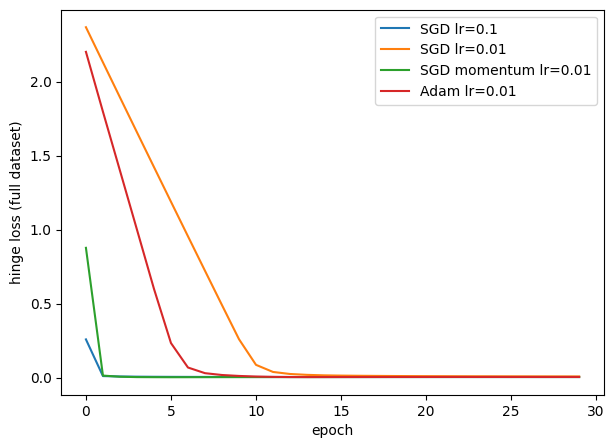

In [10]:
# comparing optimisers - recording the loss on the full dataset after every epoch
def train(opt_name, lr, epochs=30):
    torch.manual_seed(0)  # same starting w and b each time so it's a fair comparison
    w = torch.randn(1, 2, requires_grad=True)
    b = torch.randn(1, requires_grad=True)

    if opt_name == 'SGD':
        opt = optim.SGD([w, b], lr=lr, weight_decay=0.01)
    elif opt_name == 'SGD momentum':
        opt = optim.SGD([w, b], lr=lr, momentum=0.9, weight_decay=0.01)
    elif opt_name == 'Adam':
        opt = optim.Adam([w, b], lr=lr, weight_decay=0.01)

    losses = []
    for epoch in range(epochs):
        for x_batch, y_batch in dataloader:
            opt.zero_grad()
            loss = hinge_loss(svm(x_batch, w, b), y_batch)
            loss.backward()
            opt.step()
        # loss over all the data at the end of the epoch
        with torch.no_grad():
            losses.append(hinge_loss(svm(X, w, b), Y).item())
    return losses

plt.figure(figsize=(7, 5))
plt.plot(train('SGD', 0.1), label='SGD lr=0.1')
plt.plot(train('SGD', 0.01), label='SGD lr=0.01')
plt.plot(train('SGD momentum', 0.01), label='SGD momentum lr=0.01')
plt.plot(train('Adam', 0.01), label='Adam lr=0.01')
plt.xlabel('epoch')
plt.ylabel('hinge loss (full dataset)')
plt.legend()
plt.show()

In [11]:
# adding a learning rate scheduler so the steps get smaller over time (should stop the jittering)
fig = plt.figure(figsize=(5, 5))
camera = Camera(fig)

torch.manual_seed(0)
w = torch.randn(1, 2, requires_grad=True)
b = torch.randn(1, requires_grad=True)

opt = optim.SGD([w, b], lr=0.1, weight_decay=0.01)
scheduler = optim.lr_scheduler.StepLR(opt, step_size=10, gamma=0.5)  # halve the lr every 10 epochs

for epoch in range(50):
    for x_batch, y_batch in dataloader:
        opt.zero_grad()
        loss = hinge_loss(svm(x_batch, w, b), y_batch)
        loss.backward()
        opt.step()
    scheduler.step()  # update the lr once per epoch
    draw_margin(w, b, camera)

print('final lr:', opt.param_groups[0]['lr'])

anim = camera.animate()
plt.close()
HTML(anim.to_jshtml())

final lr: 0.003125
